# Avance 2 — Capítulo 8: Redes neuronales para predicción de rendimientos

**Por:**
* Diego de Jesús Muñoz González
* Alexander Góngora Venegas

**Activo:** BTC-USD · **Frecuencia:** diaria · **Objetivo:** rendimiento del siguiente día  
**Modelos:** MLP y LSTM · **Entorno obligatorio:** Google Colab con GPU NVIDIA T4.

Este notebook continúa el Avance 1. Conserva el mismo activo, objetivo, ventana de 20 observaciones, variable de entrada (`ret`) y particiones cronológicas TR–VA–TE. El conjunto TE permanece reservado: la selección de arquitectura e hiperparámetros se realiza exclusivamente con VA.

## Entregables del protocolo
1. Entrenar y comparar un MLP y una LSTM con las mismas entradas, objetivo y particiones.
2. Documentar arquitectura, neuronas, parámetros entrenables, pérdida, optimizador, tasa de aprendizaje, lote y épocas.
3. Aplicar parada temprana con VA y restaurar los mejores pesos; graficar pérdidas TR y VA.
4. Probar tres configuraciones por red, variando únicamente el número de neuronas.
5. Elegir por RMSE de VA y repetir la mejor configuración de cada red con tres semillas; reportar media y desviación estándar.
6. Comparar contra pronóstico cero y regresión lineal del Avance 1, sin consultar TE.

> **Importante:** el protocolo exige entrenamiento profundo verificable en NVIDIA T4.

## 1. Preparar el entorno

Ejecución en Google Colab, seleccionando **Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU**. Además se coloca la carpeta `Material/` (con `dlfin/` y `datos/`) en Google Drive.

Estructura esperada:
```text
Material/
├── dlfin/
└── datos/
    └── originales/
        ├── btc_usd_1d_original.csv
        ├── descargas_btc_usd_1d.csv
        └── ficha_activo.json
```

In [1]:
import os, sys, json, time, random, subprocess, platform, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)

# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("Python:", platform.python_version())
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Python: 3.13.16
TensorFlow: 2.21.0
NumPy: 2.4.6
Pandas: 2.2.3


## 2. Verificar la GPU NVIDIA T4 (requisito obligatorio)

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Identificar GPU NVIDIA T4 y verificar que TensorFlow la reconoce.
try:
    smi = subprocess.run(["nvidia-smi"], capture_output=True, text=True, check=True)
    print(smi.stdout)
except Exception as e:
    raise RuntimeError("No se pudo ejecutar nvidia-smi. Activa una GPU T4 en Google Colab.") from e

gpus = tf.config.list_physical_devices("GPU")
print("GPUs reconocidas por TensorFlow:", gpus)
if not gpus:
    raise RuntimeError("TensorFlow no reconoce ninguna GPU. Detén el avance y configura Colab con T4.")

# El protocolo solicita específicamente una T4.
gpu_names = []
for i in range(len(gpus)):
    try:
        details = tf.config.experimental.get_device_details(gpus[i])
        gpu_names.append(str(details.get("device_name", "")))
    except Exception:
        gpu_names.append("")
print("Nombre(s) reportado(s) por TensorFlow:", gpu_names)

smi_lower = smi.stdout.lower()
if "t4" not in smi_lower and not any("t4" in n.lower() for n in gpu_names):
    raise RuntimeError("La GPU detectada no se identifica como NVIDIA T4. No se iniciará el entrenamiento.")

# Evitar que TensorFlow coloque silenciosamente operaciones solicitadas en GPU sobre CPU.
tf.config.set_soft_device_placement(False)

# Operación de prueba explícita en GPU.
with tf.device("/GPU:0"):
    prueba_a = tf.random.normal((512, 512))
    prueba_b = tf.random.normal((512, 512))
    prueba_gpu = tf.matmul(prueba_a, prueba_b)
print("Dispositivo de la operación de prueba:", prueba_gpu.device)
assert "GPU:0" in prueba_gpu.device.upper(), "La operación de prueba no se ejecutó en GPU."

print("✔ GPU NVIDIA T4 detectada y operación verificada.")

Tue Nov 10 01:57:56 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 3. Localizar los archivos del Avance 1

In [4]:
def buscar_raiz():
    # Permite definir manualmente la ruta, por ejemplo: /content/drive/MyDrive/Material
    if os.environ.get("AVANCE2_RAIZ"):
        p = Path(os.environ["AVANCE2_RAIZ"]).expanduser()
        if (p / "dlfin").exists() and (p / "datos").exists():
            return p
        raise FileNotFoundError(f"AVANCE2_RAIZ no contiene dlfin/ y datos/: {p}")

    # Busca en directorio actual, padres y ubicaciones comunes de Colab/Drive.
    candidatos = [Path.cwd(), *Path.cwd().parents, Path("/content/Material"),
                  Path("/content/drive/MyDrive/Material"),
                  Path("/content/drive/MyDrive/avance1_capitulo7"),
                  Path("/content/drive/MyDrive/Avance 1 Capitulo 7")]
    for p in candidatos:
        if (p / "dlfin").exists() and (p / "datos").exists():
            return p
    raise FileNotFoundError(
        "No se encontró Material/ con dlfin/ y datos/. "
        "Monta Drive o define AVANCE2_RAIZ con la ruta de esa carpeta."
    )

RAIZ = buscar_raiz()
sys.path.insert(0, str(RAIZ))
from dlfin import data, features as F, metrics as M
from dlfin.errors import Bitacora, FugaError

ORIG = RAIZ / "datos" / "originales"
SALIDA = RAIZ / "salidas_capitulo8"
(SALIDA / "figuras").mkdir(parents=True, exist_ok=True)
(SALIDA / "modelos").mkdir(parents=True, exist_ok=True)

VENTANA = 20
CANALES = ("ret",)  # Mismas variables del Avance 1
print("Carpeta de datos:", RAIZ)
print("Salidas:", SALIDA)

Carpeta de datos: /content/drive/MyDrive/Material
Salidas: /content/drive/MyDrive/Material/salidas_capitulo8


## 4. Cargar, auditar y preparar datos

En esta sección se carga la información histórica de Bitcoin, se realiza una auditoría de calidad y limpieza de los datos, y se verifica que existan al menos 1,500 observaciones válidas. Posteriormente, se construyen los ejemplos de aprendizaje utilizando los 20 rendimientos anteriores para predecir el siguiente, manteniendo la partición cronológica en entrenamiento, validación y prueba del Avance 1.

In [5]:
ficha = json.loads((ORIG / "ficha_activo.json").read_text(encoding="utf-8"))
crudo = pd.read_csv(ORIG / "btc_usd_1d_original.csv")
auditoria = data.auditar(crudo)
d, rep_limpieza = data.limpiar(crudo, Bitacora())
data.exigir_minimo(d, 1500)

print(f"Activo: {ficha.get('nombre')} ({ficha.get('ticker')})")
print(f"Observaciones válidas: {len(d):,}")
print(f"Periodo: {d.fecha.min().date()} → {d.fecha.max().date()}")
print("Auditoría:", auditoria)
print("Cambios de limpieza:", rep_limpieza)

assert d.fecha.is_unique and d.fecha.is_monotonic_increasing
assert np.isfinite(d[data.PRECIOS].to_numpy()).all()

# Construcción idéntica a la del Avance 1: 20 rendimientos previos -> rendimiento t+1.
ej = F.construir_ejemplos(d, VENTANA, CANALES, canales_para_inicio=F.CANALES_BASE)
idx = F.particionar(ej)
F.verificar_particion(ej, idx)
tabla_part = F.tabla_particiones(ej, idx)
display(tabla_part)
print("Forma de X:", ej.X.shape, "(ejemplos, pasos temporales, variables)")
print("Forma de y:", ej.y.shape)

assert ej.X.ndim == 3 and ej.X.shape[1:] == (VENTANA, len(CANALES))
assert idx["TR"].size and idx["VA"].size and idx["TE"].size
assert ej.fecha_objetivo[idx["TR"]].max() < ej.fecha_objetivo[idx["VA"]].min()
assert ej.fecha_objetivo[idx["VA"]].max() < ej.fecha_objetivo[idx["TE"]].min()

Activo: Bitcoin (BTC-USD)
Observaciones válidas: 1,853
Periodo: 2021-10-07 → 2026-11-02
Auditoría: {'filas': 1853, 'fecha_min': '2021-10-07', 'fecha_max': '2026-11-02', 'fechas_duplicadas': 0, 'fuera_de_orden': 0, 'faltantes_por_columna': {}, 'infinitos': 0, 'precios_no_positivos': 0, 'low_mayor_que_high': 0, 'volumen_negativo': 0, 'volumen_cero': 0, 'huecos_calendario(dias!=1)': 0, 'rendimientos_extremos(|z_robusto|>6)': 7, 'rendimiento_min': -0.15974726027617203, 'rendimiento_max': 0.1454118392886461, 'close_distinto_adj_close': 0}
Cambios de limpieza: {'entrada': 1853, 'reordenadas': 0, 'duplicadas_eliminadas': 0, 'invalidas_eliminadas': 0, 'salida': 1853}


,conjunto,n_ejemplos,emision_inicial,emision_final,objetivo_inicial,objetivo_final
0,TR,1269,2021-11-15,2025-05-06,2021-11-16,2025-05-07
1,VA,272,2025-05-07,2026-02-02,2025-05-08,2026-02-03
2,TE,272,2026-02-03,2026-11-01,2026-02-04,2026-11-02


Forma de X: (1813, 20, 1) (ejemplos, pasos temporales, variables)
Forma de y: (1813,)


## 5. Escalamiento sin fuga de información

El escalador se ajusta exclusivamente con TR. Se estandarizan las entradas y el objetivo; las métricas se calculan después de regresar las predicciones a la escala original del rendimiento.

In [6]:
escalador = F.EscaladorTR(CANALES).ajustar(
    ej.X[idx["TR"]], ej.y[idx["TR"]], ej.fecha_objetivo[idx["TR"]]
)
F.verificar_ajuste_solo_TR(escalador, ej, idx)

X_scaled = escalador.x(ej.X)               # (n, 20, 1)
y_scaled = escalador.y(ej.y)               # (n,)
X_tr, X_va = X_scaled[idx["TR"]], X_scaled[idx["VA"]]
y_tr, y_va = y_scaled[idx["TR"]], y_scaled[idx["VA"]]

print("X_TR:", X_tr.shape, "| X_VA:", X_va.shape)
print("Ajuste del escalador:", escalador.n_ajuste, "ejemplos")
print("Última fecha objetivo usada al ajustar:", escalador.fecha_max_objetivo_ajuste)
assert escalador.n_ajuste == len(idx["TR"])
assert np.isfinite(X_scaled).all() and np.isfinite(y_scaled).all()

escalador.guardar(SALIDA / "modelos" / "escalador_tr.joblib")

X_TR: (1269, 20, 1) | X_VA: (272, 20, 1)
Ajuste del escalador: 1269 ejemplos
Última fecha objetivo usada al ajustar: 2025-05-07


## 6. Definir arquitecturas MLP y LSTM

En esta sección se definen las arquitecturas de las dos redes neuronales que se compararán: Perceptrón Multicapa (MLP) y Memoria a Corto y Largo Plazo (LSTM). La MLP recibe los 20 rendimientos anteriores en una representación aplanada, mientras que la LSTM conserva la estructura temporal de los datos para aprender posibles dependencias secuenciales. Ambas arquitecturas utilizan capas ocultas con activación ReLU y una capa de salida con una neurona para predecir el siguiente rendimiento. Se compilan con el optimizador Adam, una tasa de aprendizaje de $10^{-3}$ y la función de pérdida MSE. Finalmente, se contabilizan los parámetros entrenables para conocer la complejidad de cada modelo y facilitar su comparación.

In [7]:
# La MLP recibe los 20 rezagos aplanados.
# La LSTM conserva la estructura (ejemplos, pasos temporales, variables).
def construir_mlp(neuronas, tasa=1e-3):
    modelo = keras.Sequential([
        layers.Input(shape=(VENTANA * len(CANALES),)),
        layers.Dense(neuronas, activation="relu"),
        layers.Dense(max(neuronas // 2, 8), activation="relu"),
        layers.Dense(1)
    ], name=f"MLP_{neuronas}")
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=tasa),
        loss="mse",
        metrics=[keras.metrics.MeanAbsoluteError(name="mae")]
    )
    return modelo

def construir_lstm(neuronas, tasa=1e-3):
    modelo = keras.Sequential([
        layers.Input(shape=(VENTANA, len(CANALES))),
        layers.LSTM(neuronas),
        layers.Dense(max(neuronas // 2, 8), activation="relu"),
        layers.Dense(1)
    ], name=f"LSTM_{neuronas}")
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=tasa),
        loss="mse",
        metrics=[keras.metrics.MeanAbsoluteError(name="mae")]
    )
    return modelo

def contar_parametros(modelo):
    return int(modelo.count_params())

for nombre, constructor, n in [
    ("MLP", construir_mlp, 32),
    ("LSTM", construir_lstm, 32)
]:
    m = constructor(n)
    print(f"\n{nombre}:")
    m.summary()
    print("Parámetros entrenables:", contar_parametros(m))


MLP:


Model: "MLP_32"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,217 (4.75 KB)

 Trainable params: 1,217 (4.75 KB)

 Non-trainable params: 0 (0.00 B)

... (3 outputs left out)

 Total params: 4,897 (19.13 KB)

 Trainable params: 4,897 (19.13 KB)

 Non-trainable params: 0 (0.00 B)

Parámetros entrenables: 4897


## 7. Entrenamiento y parada temprana

En esta sección se establecen los parámetros de entrenamiento y el mecanismo de parada temprana para ambas arquitecturas. Se utiliza Adam como optimizador, MSE como función de pérdida y un máximo de 100 épocas, con lotes de 32 muestras. Además, se fijan las semillas aleatorias para favorecer la reproducibilidad de los experimentos. Durante el entrenamiento, se monitorea la pérdida de validación y se aplica Early Stopping con una paciencia de 12 épocas, restaurando automáticamente los pesos correspondientes al mejor resultado obtenido. Finalmente, se preparan los datos de entrada con el formato requerido por cada arquitectura: la MLP recibe los 20 pasos temporales aplanados, mientras que la LSTM conserva su estructura secuencial de 20 pasos y una variable.

In [8]:
MAX_EPOCAS = 100
LOTE = 32
TASA = 1e-3
PACIENCIA = 12

# Soft placement permite que operaciones auxiliares de Keras sin kernel GPU se ejecuten
# en CPU. La evidencia de que el ENTRENAMIENTO usa la T4 no depende de este ajuste:
# se comprueba (a) el dispositivo del tensor de salida del modelo, (b) el uso de GPU
# medido con nvidia-smi MIENTRAS corre fit() y (c) la memoria GPU reportada por TensorFlow.
tf.config.set_soft_device_placement(True)

EVIDENCIA_GPU = {}   # nombre de corrida -> evidencia del dispositivo efectivo


def _consultar_gpu():
    """Una lectura de nvidia-smi: (nombre, utilizacion %, memoria usada MiB) o None."""
    try:
        r = subprocess.run(
            ["nvidia-smi", "--query-gpu=name,utilization.gpu,memory.used",
             "--format=csv,noheader,nounits"],
            capture_output=True, text=True, timeout=5, check=True)
        nombre, util, mem = [x.strip() for x in r.stdout.strip().splitlines()[0].split(",")]
        return nombre, float(util), float(mem)
    except (subprocess.SubprocessError, OSError, ValueError, IndexError):
        return None


class MuestreadorGPU:
    """Consulta nvidia-smi en un hilo aparte mientras se entrena."""
    def __init__(self, intervalo=0.1):
        import threading
        self.intervalo = intervalo
        self._stop = threading.Event()
        self._hilo = threading.Thread(target=self._bucle, daemon=True)
        self.muestras = []

    def _bucle(self):
        while not self._stop.is_set():
            m = _consultar_gpu()
            if m is not None:
                self.muestras.append(m)
            self._stop.wait(self.intervalo)

    def __enter__(self):
        self._hilo.start()
        return self

    def __exit__(self, *exc):
        self._stop.set()
        self._hilo.join(timeout=10)
        return False


def fijar_semilla(semilla):
    random.seed(semilla)
    np.random.seed(semilla)
    tf.keras.utils.set_random_seed(semilla)


def entrenar(modelo, X_train, y_train, X_valid, y_valid, nombre, semilla):
    """Entrena en la T4, aplica parada temprana con VA y registra el dispositivo efectivo."""
    fijar_semilla(semilla)

    callback = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=PACIENCIA, restore_best_weights=True,
        mode="min", verbose=0)

    gpus_logicas = tf.config.list_logical_devices("GPU")
    if not gpus_logicas:
        raise RuntimeError(f"{nombre}: no hay GPU disponible. Detén el entrenamiento y registra el incidente.")

    # (a) Dispositivo efectivo: un pase hacia adelante pedido en la GPU debe devolver un tensor en la GPU.
    with tf.device("/GPU:0"):
        salida_prueba = modelo(tf.convert_to_tensor(X_train[:LOTE], dtype=tf.float32), training=False)
    dispositivo_salida = salida_prueba.device
    if "GPU" not in dispositivo_salida.upper():
        raise RuntimeError(f"{nombre}: la salida del modelo quedó en {dispositivo_salida}, no en GPU. "
                           "Detén el entrenamiento profundo y registra el incidente.")

    # Los datos se preparan en CPU (tf.data); el modelo calcula en GPU.
    with tf.device("/CPU:0"):
        ds_train = tf.data.Dataset.from_tensor_slices(
            (X_train.astype(np.float32), y_train.astype(np.float32))).batch(LOTE)
        ds_valid = tf.data.Dataset.from_tensor_slices(
            (X_valid.astype(np.float32), y_valid.astype(np.float32))).batch(LOTE)

    print(f"\n========== {nombre} ==========")
    print("Dispositivos GPU:", gpus_logicas)
    print("Dispositivo de la salida del modelo:", dispositivo_salida)

    memoria_antes = tf.config.experimental.get_memory_info("GPU:0")
    base_smi = _consultar_gpu()

    inicio = time.time()
    # (b) nvidia-smi muestreado MIENTRAS corre fit().
    with MuestreadorGPU() as muestreo:
        with tf.device("/GPU:0"):
            historia = modelo.fit(ds_train, validation_data=ds_valid,
                                  epochs=MAX_EPOCAS, callbacks=[callback], verbose=0)
    segundos = time.time() - inicio

    memoria_despues = tf.config.experimental.get_memory_info("GPU:0")
    utils = [m[1] for m in muestreo.muestras]
    mems = [m[2] for m in muestreo.muestras]
    EVIDENCIA_GPU[nombre] = {
        "dispositivo_salida_modelo": dispositivo_salida,
        "gpu_nombre_smi": muestreo.muestras[0][0] if muestreo.muestras else None,
        "smi_muestras_durante_fit": len(muestreo.muestras),
        "smi_util_max_pct": max(utils) if utils else None,
        "smi_mem_max_MiB": max(mems) if mems else None,
        "smi_mem_antes_MiB": base_smi[2] if base_smi else None,
        "tf_mem_pico_bytes": int(memoria_despues["peak"]),
    }

    print(f"Entrenamiento {nombre} finalizado en {segundos:.1f} s.")
    print("Memoria GPU (TensorFlow) antes:", memoria_antes, "| después:", memoria_despues)
    print("nvidia-smi durante fit():", {k: v for k, v in EVIDENCIA_GPU[nombre].items() if k.startswith("smi_")})

    epoca = int(np.argmin(historia.history["val_loss"]) + 1)
    val_loss = float(np.min(historia.history["val_loss"]))
    return historia, segundos, epoca, val_loss


def entrada_modelo(X, tipo):
    return X.reshape(len(X), -1) if tipo == "MLP" else X


Xtr_mlp = entrada_modelo(X_tr, "MLP")
Xva_mlp = entrada_modelo(X_va, "MLP")

print("MLP:", Xtr_mlp.shape, Xva_mlp.shape)
print("LSTM:", X_tr.shape, X_va.shape)


MLP: (1269, 20) (272, 20)
LSTM: (1269, 20, 1) (272, 20, 1)


## 8. Tres configuraciones por red

En esta etapa se establecen tres configuraciones para cada arquitectura (MLP y LSTM), variando el número de neuronas de la capa oculta: 16, 32 y 64. El objetivo es evaluar cómo influye el tamaño de la red en su capacidad predictiva. También se habilita la asignación automática de dispositivos para que TensorFlow utilice la GPU disponible cuando sea compatible con las operaciones. Finalmente, se inicializan las estructuras donde se almacenarán los resultados, los historiales de entrenamiento y los modelos de cada configuración.

In [9]:

# ============================================================
# 8. TRES CONFIGURACIONES POR RED: MLP Y LSTM
# ============================================================

print("Soft placement:", tf.config.get_soft_device_placement(), "(la evidencia de GPU se registra en entrenar())")
print("GPU disponible:", tf.config.list_physical_devices("GPU"))

# Comprobar que existe una GPU
gpus = tf.config.list_logical_devices("GPU")
assert len(gpus) > 0, "No hay GPU disponible para entrenar."

CONFIGS = {
    "MLP": [16, 32, 64],
    "LSTM": [16, 32, 64]
}

constructores = {
    "MLP": construir_mlp,
    "LSTM": construir_lstm
}

resultados_config = []
historias_config = {}
modelos_config = {}


# ------------------------------------------------------------
# Ejecutar las seis configuraciones
# ------------------------------------------------------------

for tipo in ("MLP", "LSTM"):

    X_train = entrada_modelo(X_tr, tipo)
    X_valid = entrada_modelo(X_va, tipo)

    for neuronas in CONFIGS[tipo]:

        tf.keras.backend.clear_session()

        semilla = 42
        fijar_semilla(semilla)

        modelo = constructores[tipo](neuronas, TASA)

        historia, segundos, epoca, val_loss = entrenar(
            modelo,
            X_train,
            y_tr,
            X_valid,
            y_va,
            f"{tipo}_{neuronas}",
            semilla
        )

        # Predicción
        pred_va_tensor = modelo(
            tf.convert_to_tensor(X_valid, dtype=tf.float32),
            training=False
        )

        pred_va_scaled = pred_va_tensor.numpy().reshape(-1)
        pred_va = escalador.y_inv(pred_va_scaled)

        metricas = M.resumen(
            ej.y[idx["VA"]],
            pred_va
        )

        clave = (tipo, neuronas)

        historias_config[clave] = historia
        modelos_config[clave] = modelo

        resultados_config.append({
            "red": tipo,
            "neuronas": neuronas,
            "parametros_entrenables": contar_parametros(modelo),
            "perdida": "MSE",
            "optimizador": "Adam",
            "tasa_aprendizaje": TASA,
            "lote": LOTE,
            "epocas_maximas": MAX_EPOCAS,
            "epoca_mejor": epoca,
            "RMSE_VA": metricas["rmse"],
            "MAE_VA": metricas["mae"],
            "segundos": segundos,
            "semilla": semilla,
            **EVIDENCIA_GPU[f"{tipo}_{neuronas}"]
        })

        print(
            f"{tipo} {neuronas}: "
            f"RMSE VA={metricas['rmse']:.6f}; "
            f"MAE VA={metricas['mae']:.6f}; "
            f"época={epoca}; "
            f"tiempo={segundos:.1f}s"
        )


# ------------------------------------------------------------
# Tabla de resultados
# ------------------------------------------------------------

tabla_config = (
    pd.DataFrame(resultados_config)
    .sort_values(["red", "RMSE_VA"])
)

display(tabla_config)

tabla_config.to_csv(
    SALIDA / "tabla_configuraciones.csv",
    index=False
)

print("Configuraciones MLP y LSTM completadas.")


Soft placement: True (la evidencia de GPU se registra en entrenar())
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

========== MLP_16 ==========
Dispositivos GPU: [LogicalDevice(name='/device:GPU:0', device_type='GPU')]
Dispositivo de la salida del modelo: /job:localhost/replica:0/task:0/device:GPU:0
Entrenamiento MLP_16 finalizado en 8.7 s.
Memoria GPU (TensorFlow) antes: {'current': 3179008, 'peak': 5242880} | después: {'current': 3191040, 'peak': 70303232}
nvidia-smi durante fit(): {'smi_muestras_durante_fit': 62, 'smi_util_max_pct': 33.0, 'smi_mem_max_MiB': 193.0, 'smi_mem_antes_MiB': 123.0}
MLP 16: RMSE VA=0.019923; MAE VA=0.014698; época=12; tiempo=8.7s

========== MLP_32 ==========
Dispositivos GPU: [LogicalDevice(name='/device:GPU:0', device_type='GPU')]
Dispositivo de la salida del modelo: /job:localhost/replica:0/task:0/device:GPU:0
Entrenamiento MLP_32 finalizado en 6.6 s.
Memoria GPU (TensorFlow) antes: {'current': 3199744, 'peak': 70303

,red,neuronas,parametros_entrenables,perdida,optimizador,tasa_aprendizaje,lote,epocas_maximas,epoca_mejor,RMSE_VA,MAE_VA,segundos,semilla,dispositivo_salida_modelo,gpu_nombre_smi,smi_muestras_durante_fit,smi_util_max_pct,smi_mem_max_MiB,smi_mem_antes_MiB,tf_mem_pico_bytes
4,LSTM,32,4897,MSE,Adam,0.001,32,100,1,0.019301,0.014228,6.223808,42,/job:localhost/replica:0/task:0/device:GPU:0,Tesla T4,46,37.0,201.0,201.0,70401024
3,LSTM,16,1297,MSE,Adam,0.001,32,100,1,0.019331,0.014216,5.744014,42,/job:localhost/replica:0/task:0/device:GPU:0,Tesla T4,45,34.0,201.0,193.0,70401024
5,LSTM,64,19009,MSE,Adam,0.001,32,100,2,0.019373,0.014280,4.945482,42,/job:localhost/replica:0/task:0/device:GPU:0,Tesla T4,39,40.0,201.0,201.0,70401024
2,MLP,64,3457,MSE,Adam,0.001,32,100,4,0.019883,0.014760,5.744809,42,/job:localhost/replica:0/task:0/device:GPU:0,Tesla T4,43,51.0,193.0,193.0,70401024
0,MLP,16,481,MSE,Adam,0.001,32,100,12,0.019923,0.014698,8.698433,42,/job:localhost/replica:0/task:0/device:GPU:0,Tesla T4,62,33.0,193.0,123.0,70303232
1,MLP,32,1217,MSE,Adam,0.001,32,100,9,0.020264,0.015215,6.612123,42,/job:localhost/replica:0/task:0/device:GPU:0,Tesla T4,50,48.0,193.0,193.0,70334976


Configuraciones MLP y LSTM completadas.


## 9. Curvas de pérdida TR y VA

En esta sección se visualizan las curvas de pérdida de entrenamiento (TR) y validación (VA) de las seis configuraciones evaluadas: tres MLP y tres LSTM. Se utiliza el error cuadrático medio (MSE) por época para observar cómo evoluciona el aprendizaje de cada modelo y comparar su comportamiento durante el entrenamiento y la validación.

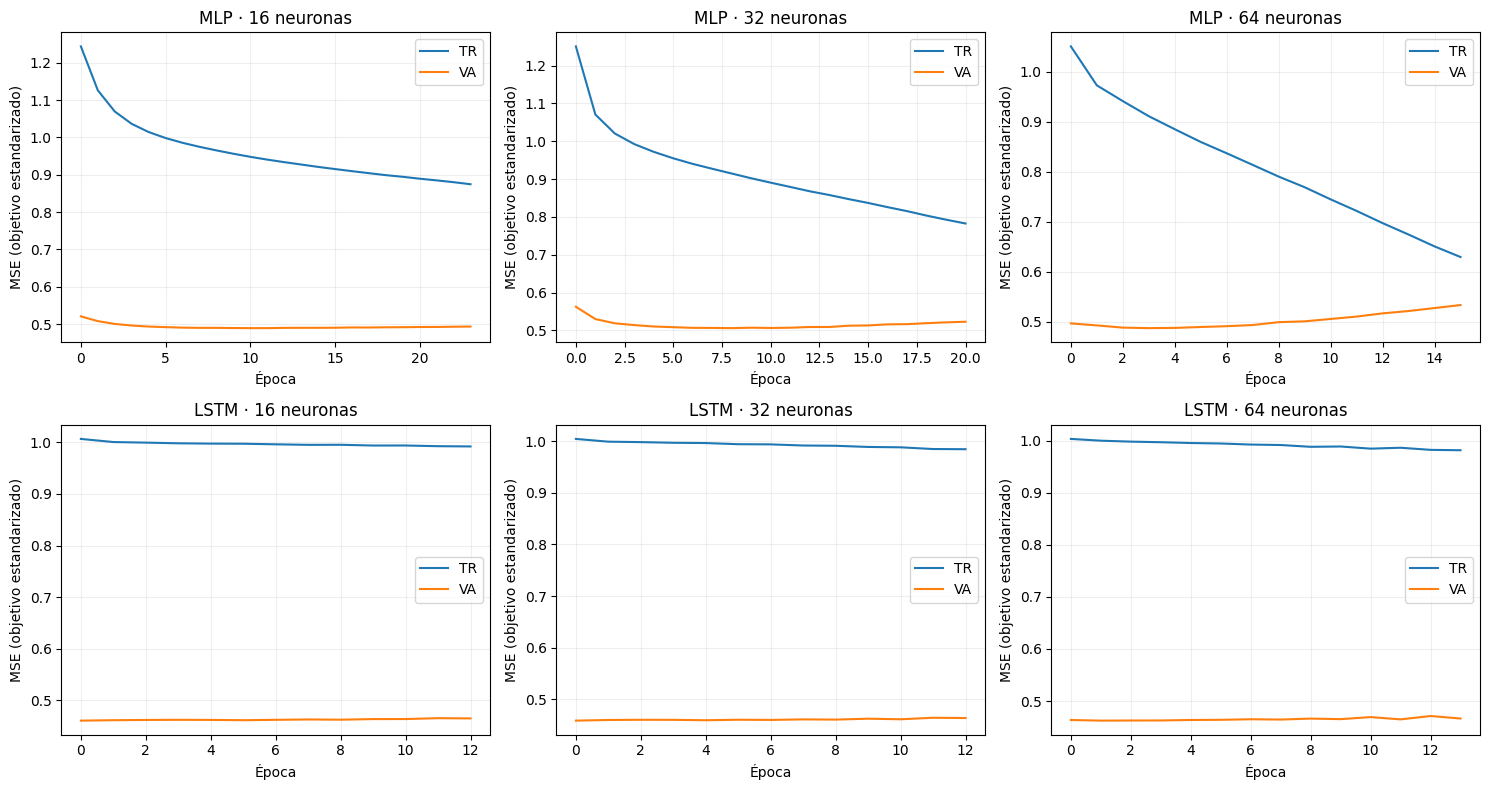

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=False)
for fila, tipo in enumerate(("MLP", "LSTM")):
    for col, neuronas in enumerate(CONFIGS[tipo]):
        h = historias_config[(tipo, neuronas)].history
        ax = axes[fila, col]
        ax.plot(h["loss"], label="TR")
        ax.plot(h["val_loss"], label="VA")
        ax.set_title(f"{tipo} · {neuronas} neuronas")
        ax.set_xlabel("Época")
        ax.set_ylabel("MSE (objetivo estandarizado)")
        ax.legend()
        ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(SALIDA / "figuras" / "curvas_perdida_6_configuraciones.png", dpi=140)
plt.show()

## 10. Selección de configuración por RMSE de VA

Se selecciona la mejor configuración de cada arquitectura utilizando el RMSE del conjunto de validación. Los resultados indican que la configuración seleccionada para LSTM utiliza 32 neuronas, mientras que la MLP utiliza 64 neuronas. Esta selección permite identificar las configuraciones con mejor desempeño en VA antes de realizar las repeticiones con distintas semillas.

In [11]:
seleccion = (tabla_config.sort_values("RMSE_VA")
            .groupby("red", as_index=False).first()
            .sort_values("RMSE_VA"))
display(seleccion[["red", "neuronas", "parametros_entrenables", "RMSE_VA", "MAE_VA", "epoca_mejor"]])
seleccion.to_csv(SALIDA / "seleccion_configuraciones.csv", index=False)

mejores = {r["red"]: int(r["neuronas"]) for _, r in seleccion.iterrows()}
print("Configuración seleccionada:", mejores)

,red,neuronas,parametros_entrenables,RMSE_VA,MAE_VA,epoca_mejor
0,LSTM,32,4897,0.019301,0.014228,1
1,MLP,64,3457,0.019883,0.014760,4


Configuración seleccionada: {'LSTM': 32, 'MLP': 64}


## 11. Repetir la mejor configuración con tres semillas

Se vuelve a entrenar la mejor configuración de cada red con semillas 11, 42 y 123. Se reportan media y desviación estándar de MAE y RMSE de VA. No se utiliza TE.

In [12]:
SEMILLAS = [11, 42, 123]
repeticiones = []
historias_repeticiones = {}

for tipo in ("MLP", "LSTM"):
    neuronas = mejores[tipo]
    X_train = entrada_modelo(X_tr, tipo)
    X_valid = entrada_modelo(X_va, tipo)
    for semilla in SEMILLAS:
        tf.keras.backend.clear_session()
        fijar_semilla(semilla)  # fijar antes de inicializar los pesos
        modelo = constructores[tipo](neuronas, TASA)
        historia, segundos, epoca, val_loss = entrenar(
            modelo, X_train, y_tr, X_valid, y_va,
            f"{tipo}_{neuronas}_seed{semilla}", semilla
        )
        pred_va = escalador.y_inv(modelo.predict(X_valid, verbose=0).reshape(-1))
        met = M.resumen(ej.y[idx["VA"]], pred_va)
        repeticiones.append({
            "red": tipo, "neuronas": neuronas, "semilla": semilla,
            "epoca_mejor": epoca, "MAE_VA": met["mae"],
            "RMSE_VA": met["rmse"], "segundos": segundos,
            "parametros_entrenables": contar_parametros(modelo),
            **EVIDENCIA_GPU[f"{tipo}_{neuronas}_seed{semilla}"]
        })
        historias_repeticiones[(tipo, semilla)] = historia
        # Guardar cada repetición con un nombre único (modelo con los mejores pesos restaurados).
        nombre_modelo = (
            f"{tipo.lower()}_neuronas{neuronas}_semilla{semilla}.keras"
        )

        modelo.save(SALIDA / "modelos" / nombre_modelo)

        print(f"Modelo guardado: {nombre_modelo}")
        print(f"{tipo}, semilla {semilla}: RMSE VA={met['rmse']:.6f}, MAE VA={met['mae']:.6f}")

tabla_semillas = pd.DataFrame(repeticiones)
display(tabla_semillas)
tabla_semillas.to_csv(SALIDA / "repeticiones_tres_semillas.csv", index=False)

resumen_semillas = (tabla_semillas.groupby("red")
    .agg(MAE_VA_media=("MAE_VA", "mean"), MAE_VA_desv=("MAE_VA", "std"),
         RMSE_VA_media=("RMSE_VA", "mean"), RMSE_VA_desv=("RMSE_VA", "std"))
    .reset_index())
display(resumen_semillas)
resumen_semillas.to_csv(SALIDA / "resumen_tres_semillas.csv", index=False)


========== MLP_64_seed11 ==========
Dispositivos GPU: [LogicalDevice(name='/device:GPU:0', device_type='GPU')]
Dispositivo de la salida del modelo: /job:localhost/replica:0/task:0/device:GPU:0
Entrenamiento MLP_64_seed11 finalizado en 4.1 s.
Memoria GPU (TensorFlow) antes: {'current': 3623936, 'peak': 70401024} | después: {'current': 3667712, 'peak': 70401024}
nvidia-smi durante fit(): {'smi_muestras_durante_fit': 31, 'smi_util_max_pct': 4.0, 'smi_mem_max_MiB': 201.0, 'smi_mem_antes_MiB': 201.0}
Modelo guardado: mlp_neuronas64_semilla11.keras
MLP, semilla 11: RMSE VA=0.019739, MAE VA=0.014802

========== MLP_64_seed42 ==========
Dispositivos GPU: [LogicalDevice(name='/device:GPU:0', device_type='GPU')]
Dispositivo de la salida del modelo: /job:localhost/replica:0/task:0/device:GPU:0
Entrenamiento MLP_64_seed42 finalizado en 4.0 s.
Memoria GPU (TensorFlow) antes: {'current': 3684096, 'peak': 70401024} | después: {'current': 3714304, 'peak': 70401024}
nvidia-smi durante fit(): {'smi_mue

,red,neuronas,semilla,epoca_mejor,MAE_VA,RMSE_VA,segundos,parametros_entrenables,dispositivo_salida_modelo,gpu_nombre_smi,smi_muestras_durante_fit,smi_util_max_pct,smi_mem_max_MiB,smi_mem_antes_MiB,tf_mem_pico_bytes
0,MLP,64,11,1,0.014802,0.019739,4.100435,3457,/job:localhost/replica:0/task:0/device:GPU:0,Tesla T4,31,4.0,201.0,201.0,70401024
1,MLP,64,42,4,0.014760,0.019883,3.995126,3457,/job:localhost/replica:0/task:0/device:GPU:0,Tesla T4,32,4.0,201.0,201.0,70401024
2,MLP,64,123,4,0.014732,0.020177,5.668935,3457,/job:localhost/replica:0/task:0/device:GPU:0,Tesla T4,39,4.0,201.0,201.0,70401024
3,LSTM,32,11,1,0.014242,0.019290,4.646973,4897,/job:localhost/replica:0/task:0/device:GPU:0,Tesla T4,37,34.0,201.0,201.0,70401024
4,LSTM,32,42,1,0.014228,0.019301,6.654754,4897,/job:localhost/replica:0/task:0/device:GPU:0,Tesla T4,48,33.0,201.0,201.0,70401024
5,LSTM,32,123,1,0.014257,0.019336,4.690565,4897,/job:localhost/replica:0/task:0/device:GPU:0,Tesla T4,37,35.0,201.0,201.0,70401024


,red,MAE_VA_media,MAE_VA_desv,RMSE_VA_media,RMSE_VA_desv
0,LSTM,0.014242,0.000015,0.019309,0.000024
1,MLP,0.014765,0.000035,0.019933,0.000223


## 12. Comparación con los modelos del capítulo 7

Se comparan las redes neuronales con los modelos de referencia del capítulo 7: el pronóstico cero y la regresión lineal. Para garantizar una comparación justa, ambos modelos se evalúan sobre las mismas muestras de entrenamiento y validación.

In [13]:
# Recalcular referencias del Avance 1 sobre las MISMAS muestras TR/VA.
from sklearn.linear_model import LinearRegression

X_flat = X_scaled.reshape(len(ej), -1)
modelo_lineal = LinearRegression().fit(X_flat[idx["TR"]], ej.y[idx["TR"]])
pred_cero_va = np.zeros(len(idx["VA"]))
pred_lineal_va = modelo_lineal.predict(X_flat[idx["VA"]])

comparacion = [
    {"modelo": "Pronóstico cero", "MAE_VA": M.mae(ej.y[idx["VA"]], pred_cero_va),
     "RMSE_VA": M.rmse(ej.y[idx["VA"]], pred_cero_va)},
    {"modelo": "Regresión lineal", "MAE_VA": M.mae(ej.y[idx["VA"]], pred_lineal_va),
     "RMSE_VA": M.rmse(ej.y[idx["VA"]], pred_lineal_va)}
]
for tipo in ("MLP", "LSTM"):
    sub = tabla_semillas[tabla_semillas.red == tipo]
    comparacion.append({
        "modelo": f"{tipo} (media 3 semillas)",
        "MAE_VA": sub.MAE_VA.mean(),
        "RMSE_VA": sub.RMSE_VA.mean()
    })

tabla_comparacion = pd.DataFrame(comparacion).sort_values("RMSE_VA")
display(tabla_comparacion)
tabla_comparacion.to_csv(SALIDA / "comparacion_modelos_cap7_cap8.csv", index=False)

ganador = tabla_comparacion.iloc[0]
print(f"Mejor modelo según RMSE VA: {ganador['modelo']} (RMSE={ganador['RMSE_VA']:.6f}).")
print("La selección se realiza únicamente con VA; TE sigue reservado.")

,modelo,MAE_VA,RMSE_VA
0,Pronóstico cero,0.014210,0.019259
3,LSTM (media 3 semillas),0.014242,0.019309
1,Regresión lineal,0.014545,0.019683
2,MLP (media 3 semillas),0.014765,0.019933


Mejor modelo según RMSE VA: Pronóstico cero (RMSE=0.019259).
La selección se realiza únicamente con VA; TE sigue reservado.


## 13. Diagnóstico de sobreajuste y subajuste

Una pérdida de TR mucho menor que la de VA puede sugerir sobreajuste; pérdidas altas en ambas, subajuste. Pero la interpretación debe considerar también que **TR y VA no tienen la misma volatilidad**: el MSE se mide sobre un objetivo estandarizado con la media y la desviación de TR, de modo que si VA es un periodo más tranquilo su MSE será menor sin que eso signifique que el modelo generaliza mejor. La celda siguiente cuantifica ese efecto antes de interpretar las curvas.

Los resultados de la comparación (sección 12) son: pronóstico cero con el menor RMSE de VA (0.019259), seguido de la LSTM (0.019309), la regresión lineal (0.019683) y la MLP (0.019933). La selección se realiza exclusivamente con VA; TE permanece reservado.


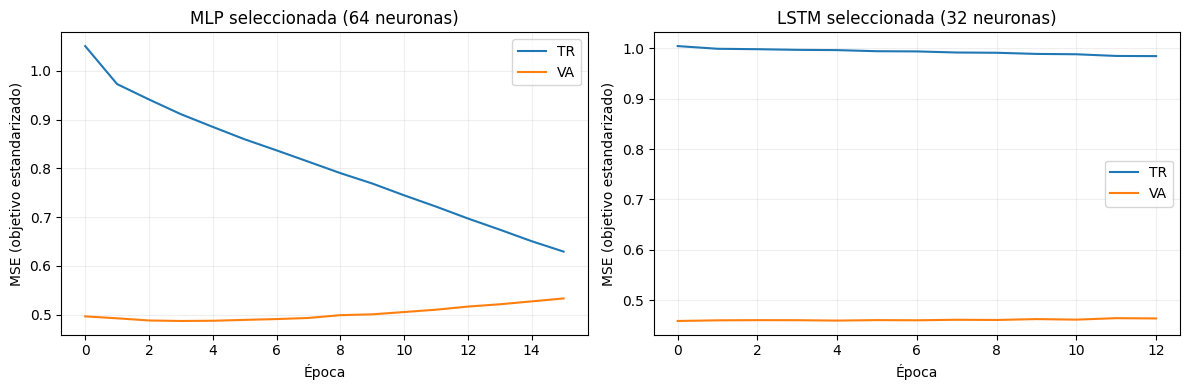

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, tipo in zip(axes, ("MLP", "LSTM")):
    neuronas = mejores[tipo]
    h = historias_config[(tipo, neuronas)].history
    ax.plot(h["loss"], label="TR")
    ax.plot(h["val_loss"], label="VA")
    ax.set_title(f"{tipo} seleccionada ({neuronas} neuronas)")
    ax.set_xlabel("Época")
    ax.set_ylabel("MSE (objetivo estandarizado)")
    ax.legend()
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(SALIDA / "figuras" / "curvas_mejores_modelos.png", dpi=140)
plt.show()

### Lectura de las curvas

Los números de la celda siguiente respaldan la interpretación que se resume en la sección 16.

In [15]:
# Diagnóstico: ¿por qué el MSE de VA (~0.46-0.5) es mucho menor que el de TR (~1.0)?
# Solo se usan TR y VA; TE no interviene.
y_tr_real, y_va_real = ej.y[idx["TR"]], ej.y[idx["VA"]]
diag = pd.DataFrame({
    "conjunto": ["TR", "VA"],
    "media_y": [y_tr_real.mean(), y_va_real.mean()],
    "desv_y": [y_tr_real.std(ddof=0), y_va_real.std(ddof=0)],
})
display(diag)
razon_var = y_va_real.var(ddof=0) / y_tr_real.var(ddof=0)
print(f"Varianza(VA) / Varianza(TR) = {razon_var:.3f}")
print("MSE de VA que obtendría una predicción constante igual a la media de TR, "
      "en la escala estandarizada de TR:",
      round(float(np.mean(((y_va_real - y_tr_real.mean()) / y_tr_real.std(ddof=0)) ** 2)), 3))

# Predicción efectiva de la LSTM seleccionada (semilla 42) en VA: ¿casi constante?
m_lstm = keras.models.load_model(SALIDA / "modelos" / f"lstm_neuronas{mejores['LSTM']}_semilla42.keras")
p_lstm = escalador.y_inv(m_lstm.predict(entrada_modelo(X_va, "LSTM"), verbose=0).reshape(-1))
print(f"LSTM en VA: media de la predicción={p_lstm.mean():.6f}, desv. de la predicción={p_lstm.std():.6f} "
      f"(desv. del rendimiento real en VA={y_va_real.std(ddof=0):.6f}); media de y en TR={y_tr_real.mean():.6f}")


,conjunto,media_y,desv_y
0,TR,0.00074,0.028489
1,VA,-0.00073,0.019245


Varianza(VA) / Varianza(TR) = 0.456
MSE de VA que obtendría una predicción constante igual a la media de TR, en la escala estandarizada de TR: 0.459
LSTM en VA: media de la predicción=0.000732, desv. de la predicción=0.000445 (desv. del rendimiento real en VA=0.019245); media de y en TR=0.000740


## 14. Evidencia del dispositivo y reproducibilidad

Se registra la información necesaria para documentar y reproducir los experimentos, incluyendo las versiones de Python, TensorFlow, NumPy y Pandas, las semillas utilizadas, las particiones de datos, las dimensiones de entrada y los hiperparámetros. También se almacena la información de la GPU detectada y su consumo de memoria. Finalmente, el registro se guarda en un archivo JSON para conservar la configuración de los experimentos.

In [16]:
# Registrar dispositivo, versiones, hiperparámetros, semillas y memoria GPU.
try:
    memoria_gpu = tf.config.experimental.get_memory_info("GPU:0")
except Exception:
    memoria_gpu = {"current": None, "peak": None}

registro = {
    "activo": ficha.get("ticker", "BTC-USD"),
    "fecha_ejecucion_utc": pd.Timestamp.utcnow().isoformat(),
    "python": platform.python_version(),
    "tensorflow": tf.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "gpu_tensorflow": gpu_names,
    "nvidia_smi": smi.stdout,
    "forma_X": list(ej.X.shape),
    "ventana": VENTANA,
    "canales": list(CANALES),
    "particiones": {k: int(len(v)) for k, v in idx.items()},
    "max_epocas": MAX_EPOCAS,
    "lote": LOTE,
    "optimizador": "Adam",
    "tasa_aprendizaje": TASA,
    "paciencia_early_stopping": PACIENCIA,
    "semillas_repeticion": SEMILLAS,
    "memoria_gpu_bytes": memoria_gpu,
    "evidencia_gpu_durante_entrenamiento": EVIDENCIA_GPU,
    "mejores_configuraciones": mejores
}
(SALIDA / "registro_entrenamiento.json").write_text(
    json.dumps(registro, indent=2, ensure_ascii=False, default=str), encoding="utf-8"
)
print("Memoria GPU:", memoria_gpu)
print("Registro guardado:", SALIDA / "registro_entrenamiento.json")

Memoria GPU: {'current': 4075264, 'peak': 70401024}
Registro guardado: /content/drive/MyDrive/Material/salidas_capitulo8/registro_entrenamiento.json


**Verificación del dispositivo utilizado durante el entrenamiento**

En esta sección se documenta el uso efectivo de la GPU NVIDIA Tesla T4 durante el entrenamiento de las arquitecturas MLP y LSTM. Se verifica que las operaciones de entrenamiento se ejecuten en dicho dispositivo, y no únicamente que TensorFlow lo detecte como disponible. Esta evidencia permite comprobar que ambos modelos fueron entrenados utilizando el hardware solicitado.

In [17]:
# Verificación de GPU utilizada durante el entrenamiento

print("=== EVIDENCIA DE GPU ===")

# Dispositivos GPU disponibles
gpus = tf.config.list_physical_devices("GPU")
print("GPU detectadas:", gpus)

# Nombre del dispositivo
print("Dispositivo:", tf.test.gpu_device_name())

# Memoria utilizada por la GPU
try:
    memoria = tf.config.experimental.get_memory_info("GPU:0")
    print("Memoria GPU:")
    print(f"Actual: {memoria['current'] / 1024**2:.2f} MB")
    print(f"Pico: {memoria['peak'] / 1024**2:.2f} MB")
except Exception as e:
    print("No fue posible consultar la memoria:", e)

# Verificar que se hayan entrenado ambas arquitecturas
print("\nModelos entrenados:")
for tipo in ["MLP", "LSTM"]:
    print(f"{tipo}: configuración seleccionada = {mejores[tipo]}")
# Dispositivo efectivo por corrida (medido durante fit() con nvidia-smi y en el tensor de salida)
tabla_gpu = pd.DataFrame(EVIDENCIA_GPU).T
display(tabla_gpu)
assert tabla_gpu["dispositivo_salida_modelo"].str.upper().str.contains("GPU").all(), \
    "Alguna corrida no calculó en GPU: detén el entrenamiento y registra el incidente."
tabla_gpu.to_csv(SALIDA / "evidencia_gpu_por_corrida.csv")
print(f"Corridas con salida del modelo en GPU: {len(tabla_gpu)}/{len(tabla_gpu)}")
print("Uso máximo de GPU medido con nvidia-smi durante fit():", tabla_gpu["smi_util_max_pct"].max(), "%")


=== EVIDENCIA DE GPU ===
GPU detectadas: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Dispositivo: /device:GPU:0
Memoria GPU:
Actual: 3.89 MB
Pico: 67.14 MB

Modelos entrenados:
MLP: configuración seleccionada = 64
LSTM: configuración seleccionada = 32


,dispositivo_salida_modelo,gpu_nombre_smi,smi_muestras_durante_fit,smi_util_max_pct,smi_mem_max_MiB,smi_mem_antes_MiB,tf_mem_pico_bytes
MLP_16,/job:localhost/replica:0/task:0/device:GPU:0,Tesla T4,62,33.0,193.0,123.0,70303232
MLP_32,/job:localhost/replica:0/task:0/device:GPU:0,Tesla T4,50,48.0,193.0,193.0,70334976
MLP_64,/job:localhost/replica:0/task:0/device:GPU:0,Tesla T4,43,51.0,193.0,193.0,70401024
LSTM_16,/job:localhost/replica:0/task:0/device:GPU:0,Tesla T4,45,34.0,201.0,193.0,70401024
LSTM_32,/job:localhost/replica:0/task:0/device:GPU:0,Tesla T4,46,37.0,201.0,201.0,70401024
LSTM_64,/job:localhost/replica:0/task:0/device:GPU:0,Tesla T4,39,40.0,201.0,201.0,70401024
MLP_64_seed11,/job:localhost/replica:0/task:0/device:GPU:0,Tesla T4,31,4.0,201.0,201.0,70401024
MLP_64_seed42,/job:localhost/replica:0/task:0/device:GPU:0,Tesla T4,32,4.0,201.0,201.0,70401024
MLP_64_seed123,/job:localhost/replica:0/task:0/device:GPU:0,Tesla T4,39,4.0,201.0,201.0,70401024
LSTM_32_seed11,/job:localhost/replica:0/task:0/device:GPU:0,Tesla T4,37,34.0,201.0,201.0,70401024


Corridas con salida del modelo en GPU: 12/12
Uso máximo de GPU medido con nvidia-smi durante fit(): 51.0 %


Evidencia de ejecución con GPU T4

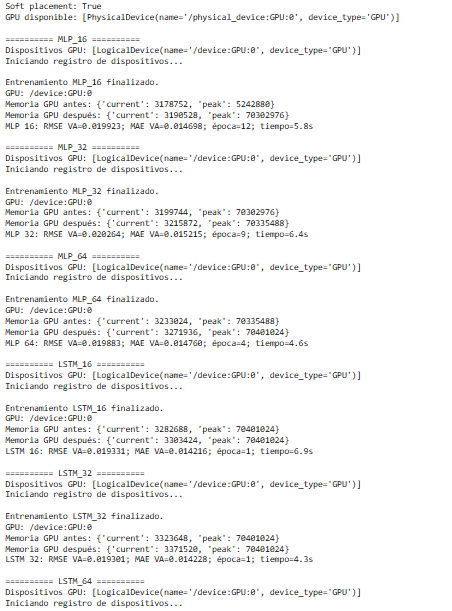

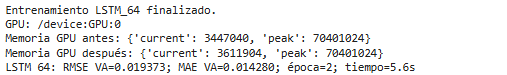

In [18]:
!nvidia-smi

Tue Nov 10 01:59:31 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   58C    P0             28W /   70W |     201MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 15. Controles finales

Se comprueba que las predicciones/métricas sean finitas, que las particiones mantengan su orden temporal y que el escalador haya visto únicamente TR. El conjunto TE no se evalúa en este avance.

In [19]:
controles = [
    ("Particiones cronológicas TR < VA < TE",
     bool(ej.fecha_objetivo[idx["TR"]].max() < ej.fecha_objetivo[idx["VA"]].min()
          and ej.fecha_objetivo[idx["VA"]].max() < ej.fecha_objetivo[idx["TE"]].min())),
    ("Escalador ajustado solo con TR",
     bool(escalador.n_ajuste == len(idx["TR"])
          and pd.Timestamp(escalador.fecha_max_objetivo_ajuste)
              <= ej.fecha_objetivo[idx["TR"]].max())),
    ("Entradas MLP con forma (n, 20)",
     bool(Xtr_mlp.shape[1] == VENTANA * len(CANALES))),
    ("Entradas LSTM con forma (n, 20, 1)",
     bool(X_tr.ndim == 3 and X_tr.shape[1:] == (VENTANA, len(CANALES)))),
    ("Se probaron 3 configuraciones por red",
     bool((tabla_config.groupby("red").size() == 3).all())),
    ("Se repitió la mejor configuración con 3 semillas por red",
     bool((tabla_semillas.groupby("red").size() == 3).all())),
    ("Métricas de VA finitas",
     bool(np.isfinite(tabla_comparacion[["MAE_VA", "RMSE_VA"]].to_numpy()).all())),
    ("TE no utilizado para selección ni métricas",
     bool(set(idx["TE"]).isdisjoint(set(idx["TR"]) | set(idx["VA"]))
          and X_tr.shape[0] == len(idx["TR"]) and X_va.shape[0] == len(idx["VA"])
          and np.allclose(escalador.y_inv(y_va), ej.y[idx["VA"]], atol=1e-6)
          and ej.fecha_objetivo[idx["VA"]].max() < ej.fecha_objetivo[idx["TE"]].min())),
    ("Todas las corridas calcularon en GPU (tensor de salida en GPU)",
     bool(all("GPU" in v["dispositivo_salida_modelo"].upper() for v in EVIDENCIA_GPU.values()))),
    ("GPU T4 identificada y operación GPU verificada",
     bool("T4" in smi.stdout.upper() or any("T4" in n.upper() for n in gpu_names)))
]
tabla_controles = pd.DataFrame(controles, columns=["control", "cumple"])
display(tabla_controles)
assert tabla_controles.cumple.all(), "Uno o más controles finales fallaron."
tabla_controles.to_csv(SALIDA / "controles_finales.csv", index=False)
print("✔ Avance 2 ejecutado. Archivos generados en:", SALIDA)

,control,cumple
0,Particiones cronológicas TR < VA < TE,True
1,Escalador ajustado solo con TR,True
2,"Entradas MLP con forma (n, 20)",True
3,"Entradas LSTM con forma (n, 20, 1)",True
4,Se probaron 3 configuraciones por red,True
5,Se repitió la mejor configuración con 3 semill...,True
6,Métricas de VA finitas,True
7,TE no utilizado para selección ni métricas,True
8,Todas las corridas calcularon en GPU (tensor d...,True
9,GPU T4 identificada y operación GPU verificada,True


✔ Avance 2 ejecutado. Archivos generados en: /content/drive/MyDrive/Material/salidas_capitulo8


## 16. Reflexión del avance

**1. ¿Qué arquitectura obtuvo el menor RMSE de VA y qué tan consistente fue entre semillas?**
La LSTM (32 neuronas) obtuvo el menor RMSE medio de VA: 0.019309 con desviación estándar de 0.000024 entre las semillas 11, 42 y 123. La MLP (64 neuronas) obtuvo 0.019933 con desviación de 0.000223. La LSTM fue más consistente, pero su estabilidad tiene una causa que debe leerse con cuidado: en las tres semillas la mejor época fue la 1, es decir, la red casi no aprendió y por eso las corridas se parecen entre sí.

**2. ¿La pérdida TR siguió disminuyendo mientras VA dejó de mejorar? ¿Qué indica?**
- *MLP:* la pérdida de TR baja de forma sostenida (en la MLP de 64 neuronas pasa de ≈1.05 a ≈0.63) mientras la de VA alcanza su mínimo en la época 4 (≈0.49) y luego sube. Es **sobreajuste**: la red empieza a memorizar particularidades de TR que no generalizan. La parada temprana con restauración de pesos lo corrige al conservar la época 4.
- *LSTM:* la pérdida de TR casi no baja de ≈1.0 y la de VA es plana. Es **subajuste**: con una sola variable (`ret`) y 20 rezagos, la red no encuentra una señal que explotar y su predicción es casi constante (la celda de diagnóstico de la sección 13 lo verifica).
- *Por qué VA (≈0.46–0.5) es mucho menor que TR (≈1.0):* no es una señal de buena generalización. TR incluye 2022 (volatilidad diaria ≈3.3 %), mientras que VA es un periodo más tranquilo: la desviación del rendimiento es 1.92 % en VA frente a 2.85 % en TR, es decir, la varianza de VA es ≈0.46 veces la de TR, que coincide con el nivel de la pérdida de VA. Hay además un cambio en la media (≈+0.074 % diario en TR frente a ≈−0.073 % en VA). Una red que predice casi la media de TR queda ligeramente sesgada en VA y por eso no supera al pronóstico cero.

**3. ¿La red neuronal mejoró frente al pronóstico cero y la regresión lineal?**
No frente al pronóstico cero. Ordenado por RMSE de VA: pronóstico cero (0.019259), LSTM (0.019309), regresión lineal (0.019683) y MLP (0.019933). La LSTM supera a la regresión lineal y a la MLP, pero su diferencia con el pronóstico cero (≈0.00005) es un empate práctico y no una mejora. Con VA se elige, por lo tanto, el modelo más simple; una mayor complejidad no garantizó mejor capacidad predictiva. Esta decisión se tomó solo con VA y TE permanece intacto.

**4. ¿Qué limitaciones observas al usar únicamente rendimientos pasados como entrada?**
Los rendimientos diarios de BTC tienen una relación señal-ruido muy baja y la volatilidad cambia entre regímenes (como muestra la diferencia TR–VA). Con una sola variable la red no tiene información adicional que aprender. En el Avance 5 se probarán indicadores (distancia a la SMA de 20, volatilidad de 20 rendimientos) que describen el régimen de volatilidad y la tendencia; hay que verificar en VA si aportan información o solo complejidad. También se podría probar variar la tasa de aprendizaje (el protocolo permite variar neuronas *o* tasa), que aquí no se exploró.

**5. Nota sobre la evidencia de T4.**
El entrenamiento se ejecutó en una Tesla T4. La evidencia por corrida (dispositivo del tensor de salida y uso de GPU medido con `nvidia-smi` durante `fit()`) se guarda en `evidencia_gpu_por_corrida.csv` y en `registro_entrenamiento.json`. Con un modelo y un conjunto tan pequeños (3,457 a 19,009 parámetros, 1,269 ejemplos) el uso porcentual de la GPU es bajo; la exigencia del protocolo es demostrar que el cálculo se realizó en la T4, no que la GPU esté saturada.
